In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import scipy.stats as stats
import re

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")
import builtins
    
builtins.NAMING = "new"

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *
from RealTrace_paper_analysis.plotting_src.plot_correlations_from_npz import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [56]:
filenames = ["../../ecoli_other_labs/Kar2021/alanine_upload.txt",
             "../../ecoli_other_labs/Kar2021/glycerol_upload.txt",
             "../../ecoli_other_labs/Kar2021/glucose_cas_upload.txt"]

# for file in filenames:
#     process_file(file)

filenames_extended = [f.replace("_upload.txt", "_extended_upload.txt") for f in filenames]

In [140]:
def find_parent(meas, extended):
    meas_str = "_".join( np.round(np.diff(meas)[:10], 2).astype(str))
    for cell in extended.keys():
        if meas_str in extended[cell]:
            return cell
    


def get_time_diff(data_df):
    unique_Tns = np.unique(data_df[data_df["t-BirthFrame"] == "Tn"].to_numpy()[0][2:])
    return np.min(np.diff(np.sort(unique_Tns)))



def process_cell(raw_data_row, dt):
    data = raw_data_row[2:]
    meas = data[np.isfinite(data)].to_numpy()
    time = np.arange(len(meas))*dt + raw_data_row[1]
    return time, meas


def process_extended_cell(raw_data_row):
    data = raw_data_row[3:]
    meas = data[np.isfinite(data)].to_numpy()
    return meas


def process_file(filename):
    outfile = filename.replace("_upload.txt", "_processed.csv")
    raw_data = pd.read_csv( filename ,delimiter="\t")
    
    cell_ids = raw_data.columns[1:]
    dt = get_time_diff(raw_data)

    # extended_data = pd.read_csv( filename.replace("_upload.txt", "_extended_upload.txt"),
    #                         delimiter="\t")
    # extended_data_dict ={}
    # for cell_id in cell_ids:
    #     if cell_id in extended_data.keys():
    #         meas = process_extended_cell(extended_data[cell_id])
    #         print(np.round(np.diff(meas), 2))
    #         extended_data_dict[cell_id] = "_".join( np.round(np.diff(meas), 2).astype(str))
    #     else:
    #         pass    
            
    dataset = pd.DataFrame()
    
    for cell_id in cell_ids[:100]:
        time, meas = process_cell(raw_data[cell_id], dt)
        
        cell_df = pd.DataFrame({ "time":time, "length_um": meas})
        cell_df["cell_id"]=cell_id
        
        dataset = pd.concat([dataset, cell_df], ignore_index=True)
        
    return
    dataset["dummy_gfp"] = np.random.normal(loc=0, scale=1e-3, size=len(dataset["time"]))
    dataset["parent_id"] = -1
    dataset.to_csv(outfile)

for file in filenames:
    _= process_file(file)
    break

In [3]:
for file in filenames: 
    print(file, "\n")
    out_dir = os.path.join(*file.split("/")[:-1], "RealTrace_out")
    outfile = file.replace("_upload.txt", "_processed.csv")
    
    param_file = os.path.join(*file.split("/")[:-1], "parameters.txt")
    config_file = os.path.join(*file.split("/")[:-1], "csv_config.txt")
    
    run_cmd = "../../RealTrace/bin/RealTrace" + \
            " -c " + config_file + \
            " -b " + param_file + \
            " -t " + str(1e-40) + \
            " -i " + outfile + \
            " -o " + out_dir + \
            " -noise const" + \
            " -space log" +\
            " -m -p -j"
    print("run: -> \n", run_cmd)
    # s = subprocess.run(run_cmd, capture_output=True, shell=True)
    # print(s)

../../ecoli_other_labs/Kar2021/alanine_upload.txt 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kar2021/csv_config.txt -b ../../ecoli_other_labs/Kar2021/parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kar2021/alanine_processed.csv -o ../../ecoli_other_labs/Kar2021/RealTrace_out -noise const -space log -m -p -j
../../ecoli_other_labs/Kar2021/glycerol_upload.txt 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kar2021/csv_config.txt -b ../../ecoli_other_labs/Kar2021/parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kar2021/glycerol_processed.csv -o ../../ecoli_other_labs/Kar2021/RealTrace_out -noise const -space log -m -p -j
../../ecoli_other_labs/Kar2021/glucose_cas_upload.txt 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kar2021/csv_config.txt -b ../../ecoli_other_labs/Kar2021/parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kar2021/glucose_cas_processed.csv -o ../../ecoli_other_labs/Kar2021/RealTrace_out -noise const -s

In [141]:
# ! python3 ../../RealTrace/python_src/correlation_from_joint.py -d ../../ecoli_other_labs/Kar2021/RealTrace_out -k processed -dt 4



In [184]:
color_by_condition_Kar = {'alanine': "tab:red",
                'glycerol': "tab:blue",
                'glucose_cas': "tab:purple"}

alanine
glycerol
glucose_cas


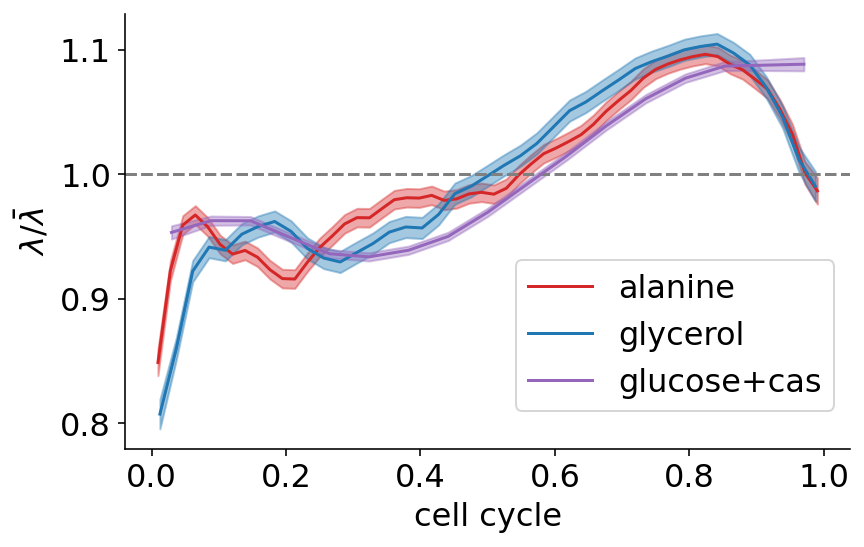

In [185]:
def added_volume_dependence_all_without_cdf(all_filenames,  
                            xlim=[None, None], 
                            ylim=[None, None],
                            hist_xlim=[None, None],
                            outfile=None, 
                            show=True, 
                            norm_q=False, 
                            norm_l=False,
                            plot_scatter=False,
                            plot_all=False,
                            xaxis_parameter="volume",
                            alignment="norm", 
                            growth_rate_unit=60,
                            label="both",
                            title=None,
                            interpolate=None,
                            color_code="condition", 
                            bins=10, 
                            show_cc_corr=False,
                           legend=True):
    
    # fig, ax0 = plt.subplots(1,1, figsize=(FULL_SIZE, FULL_HEIGHT*1.5), sharex=True)
    fig, ax0 = plt.subplots(1,1, figsize=(FULL_SIZE/2,FULL_HEIGHT))

    condis = [file.split("_processed")[0].split("/")[-1] for file in all_filenames]
    for i, condition in enumerate(condis):
        filenames = [file for file in all_filenames if condition in file.split("/")[-1]]    

        print(condition)
                               
        for a in [ax0]:
            a.spines["top"].set_visible(False)
            a.spines["right"].set_visible(False)
            a.spines['right'].set_color('none')
            a.yaxis.tick_left()
            a.spines['top'].set_color('none')
            a.xaxis.tick_bottom()

        longest_cc = []

        for filename in filenames:
            data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
    
            data = pd.read_csv(filename, skiprows=header_lines(filename))
            cells_data = df2ggp_cells(data)

            collect_mean_l = np.array([])
            collect_var_l = np.array([])

            collect_mean_q = np.array([])
            collect_var_q = np.array([])

            xaxis = np.array([])
            xaxis_cc = np.array([])
            if interpolate!=None:
                if interpolate=="auto":
                    n_d = 0
                    for cell in cells_data:
                        n_d += len(cell.time)
                    n_interpolate=int(n_d/len(cells_data))
                    bins=n_interpolate
                else:
                    n_interpolate = interpolate
                    bins=n_interpolate

            for _, cell in enumerate(cells_data):
                if len(cell.time)<2:
                    continue

                if xaxis_parameter == "volume":
                    single_cell_xaxis = np.exp(cell.mean_x)
                elif xaxis_parameter == "time":
                    single_cell_xaxis = np.array(cell.time)

                if alignment=="norm":                    
                    dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                        / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                elif alignment== "birth":
                    dx = single_cell_xaxis - single_cell_xaxis[0]
                else:
                    return

                if interpolate!=None:
                    linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                    cell.mean_l=np.interp(linspace, dx, cell.mean_l)
                    cell.cov_ll=np.interp(linspace, dx, cell.cov_ll)

                    cell.mean_q=np.interp(linspace, dx, cell.mean_q)
                    cell.cov_qq=np.interp(linspace, dx, cell.cov_qq)
                    dx = linspace


                xaxis_cc = np.append(xaxis_cc, single_cell_xaxis[-1] - single_cell_xaxis[0])
                xaxis = np.append(xaxis, dx)

                collect_mean_l = np.append(collect_mean_l, cell.mean_l)
                collect_var_l = np.append(collect_var_l, cell.cov_ll)

                collect_mean_q = np.append(collect_mean_q, cell.mean_q)
                collect_var_q = np.append(collect_var_q, cell.cov_qq)

            mean_l, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_l,statistic='mean', bins=bins)
            sum_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='sum', bins=bins)
            count_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='count', bins=bins)
            std_l = np.sqrt(sum_l / count_l**2)

            if norm_l:
                ax0.axhline(1, color="grey", ls='--')
                normalization_l = np.mean(collect_mean_l)
                mean_l = mean_l/normalization_l
                std_l = std_l/normalization_l
                collect_mean_l/=normalization_l


            ax0.plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l, 
                     label=condition.replace("_", "+"), 
                    color=color_by_condition_Kar[condition])
            ax0.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2,
                             mean_l+std_l, 
                             mean_l-std_l, 
                            alpha=0.4, 
                            color=color_by_condition_Kar[condition])
            
            if plot_all:
                for _, cell in enumerate(cells_data[:20]):

                    if xaxis_parameter == "volume":
                        single_cell_xaxis = np.exp(cell.mean_x)
                    elif xaxis_parameter == "time":
                        single_cell_xaxis = np.array(cell.time)

                    if alignment=="norm":                    
                        dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                            / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                    elif alignment== "birth":
                        dx = single_cell_xaxis - single_cell_xaxis[0]
                    else:
                        return

                    if interpolate!=None:
                        linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                        dx = linspace
                    ax0.plot(dx, cell.mean_l/normalization_l, color="tab:grey", zorder=-10, alpha=0.05)

        ax0.set_ylabel(r"$\lambda/\bar{\lambda}$")   
        ax0.set_xlabel("cell cycle")  

        # if i==0:
        #     # ax1.legend(loc='upper right', bbox_to_anchor=(1,1.1), ncol=2,  title_fontsize=MEDIUM_SIZE)
        #     ax1.legend(loc='center left', bbox_to_anchor=(0.98, 0.5), ncol=1,  title_fontsize=MEDIUM_SIZE)
        # if i==2:
        #     for a in [ax0, ax1]:
        #         a.set_xlabel("cell cycle")  
        #         a.set_xticks(np.arange(0, 1.25, 0.25))
        #         a.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])

    ax0.legend(ncol=1, loc="lower right", bbox_to_anchor=(1,0.05))

    if outfile != None:
        fig.savefig(outfile.format(xaxis_parameter, alignment), dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
# ==================================================== #

prediction_files = get_suffix_files("../../ecoli_other_labs/Kar2021/RealTrace_out/", suffix='prediction.csv') 

added_volume_dependence_all_without_cdf(prediction_files[:],  
                                # outfile=os.path.join("../../figures_for_method_paper/plots_main/cell_cycle/all_cellc_cycle_dependencies.pdf" ), 
                                show=False, 
                                norm_l=True, 
                                norm_q=True, 
                                        # plot_all=True,
                                xaxis_parameter="volume",
                                alignment="norm", 
                                interpolate="auto",
                                legend=True)




In [150]:
prediction_files = get_suffix_files("../../ecoli_other_labs/Kar2021/RealTrace_out/", suffix='prediction.csv') 
prediction_files

['../../ecoli_other_labs/Kar2021/RealTrace_out/alanine_processed_f01279_b_prediction.csv',
 '../../ecoli_other_labs/Kar2021/RealTrace_out/glycerol_processed_f01279_b_prediction.csv',
 '../../ecoli_other_labs/Kar2021/RealTrace_out/glucose_cas_processed_f01279_b_prediction.csv']

In [143]:
### Get rate stats ###

def calc_cv(means, covs=None):
    if np.any(covs==None):
        return np.std(means)/np.mean(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)/np.mean(means)

def calc_std(means, covs=None):
    if np.any(covs==None):
        return np.std(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)
    
def calc_mean(means, covs=None):
    if np.any(covs==None):
        mean = np.mean(means)
    else:
        mean = np.sum(means/covs) /np.sum(1/covs)
    return mean

def estimate_rate_stats(filename):
    
    data_prediction = pd.read_csv(filename, skiprows=header_lines(filename))
    cells_prediction = ggp_df2cells(data_prediction)
    cell_stats = {}
    for i in ["l", "q"]:
        zi = "{:s}t".format(i)
        zi_cov = "cov_{:s}{:s}".format(i, i)

        zi_coll_prediction = np.concatenate([cell.__dict__[zi] for cell in cells_prediction])
        zi_coll_prediction_err = np.concatenate([cell.__dict__[zi_cov] for cell in cells_prediction])
        cell_stats["{:s}_mean".format(i)] = calc_mean(zi_coll_prediction, zi_coll_prediction_err)
        cell_stats["{:s}_cv".format(i)] = calc_cv(zi_coll_prediction, zi_coll_prediction_err)
        cell_stats["{:s}_std".format(i)] = calc_std(zi_coll_prediction, zi_coll_prediction_err)

    cell_stats["q_cv/l_cv"]= cell_stats["q_cv"]/ cell_stats["l_cv"]
    ## Adj. units lambda in 1/h, q in 1000/h
    cell_stats['l_mean']*=60
    cell_stats['l_std']*=60

    cell_stats["l"] = np.concatenate([cell.__dict__['lt'] for cell in cells_prediction])
    
    cell_stats['q_mean']*=60/1000
    cell_stats['q_std']*=60/1000

    sample = "_".join(filename.split("/")[-1].split(".")[0].split("_")[:3])
    cell_stats["sample"]= sample
    
    cell_stats["condition"] = filename.split("/")[-1].split("_")[0]
    cell_stats["promoter"] = filename.split("/")[-1].split("_")[1]
    return cell_stats


all_files_dany = sorted(find_files("../../data_realtrace_paper/ecoli_data/", ending="prediction.csv"))

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']
conditions_to_plot = conditions[:3]

all_files_dany = [file for file in all_files_dany if file.split("/")[-1].split("_")[0] in conditions_to_plot and file.split("/")[-1].split("_")[1] in promoters_to_plot]        
all_files_dany = sort_by_condition(all_files_dany)



cell_stats = {}
for file in prediction_files :
    data_set_name = file.split("/")[-1].split("_rawdata")[0]
    print("|", end="")
    cell_stats[data_set_name] = estimate_rate_stats(file)
    cell_stats[data_set_name]["source"] = "Kar et al. 2021"


for file in  all_files_dany :
    data_set_name = file.split("/")[-1].split("_rawdata")[0]
    print("|", end="")
    cell_stats[data_set_name] = estimate_rate_stats(file)
    cell_stats[data_set_name]["source"] = "this study"


|||||||||||||||

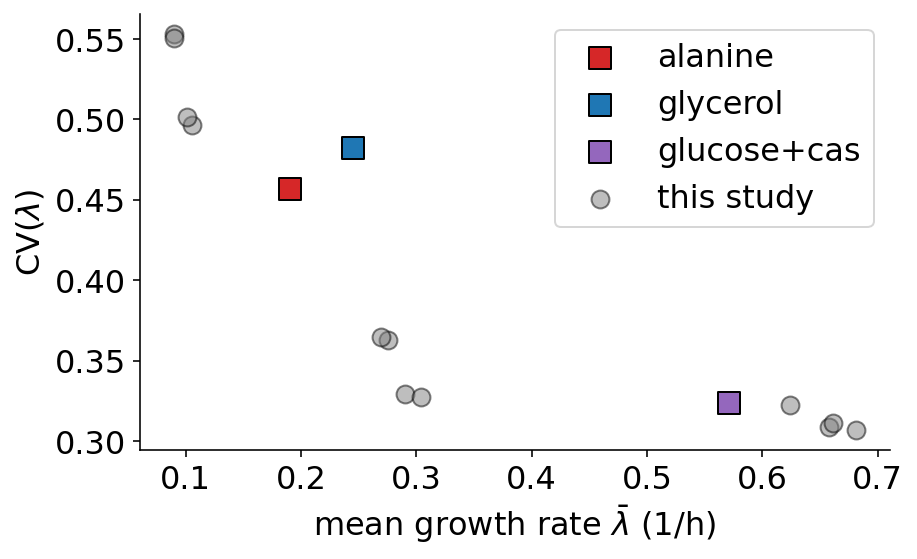

In [186]:

def plot_growth_rate_stats(cell_stats, plot_file=None, color_scheme =None):
    fig, ax = plt.subplots(1,1, figsize=(FULL_SIZE/2,FULL_HEIGHT))
    
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
    
    days = {}
    color_i = 0
    ax.set_xlabel(r"mean growth rate $\bar{\lambda}$ (1/h)")
    ax.set_ylabel(r"CV($\lambda$)")
    for k in cell_stats.keys():    
        condition = k.split("_pro")[0]
        if cell_stats[k]["source"]=="this study":
            color="tab:grey"
            label=None
            alpha=0.5
            s=80
            marker="o"
            label="this study"
        else:
            color=color=color_by_condition_Kar[condition]
            label=condition.replace("_", "+")
            alpha=1
            s=120
            marker="s"    
        ax.scatter(cell_stats[k]["l_mean"], cell_stats[k]["l_cv"], 
                    s=s,
                   marker=marker,
                   color=color,
                    ec="black", 
                      label=label, 
                  alpha=alpha)
    ax.yaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=0.05))
    

    ax.legend(*legend_without_duplicate_labels(ax), 
            loc='upper right', 
            bbox_to_anchor=(1, 1), 
            ncol=1)
    

    plt.tight_layout()

    if plot_file != None:
        print("Saved in", plot_file)
        fig.savefig(plot_file, dpi=300, facecolor="white", bbox_inches="tight")
        plt.show()

    
    plt.show()
    


plot_growth_rate_stats(cell_stats,)



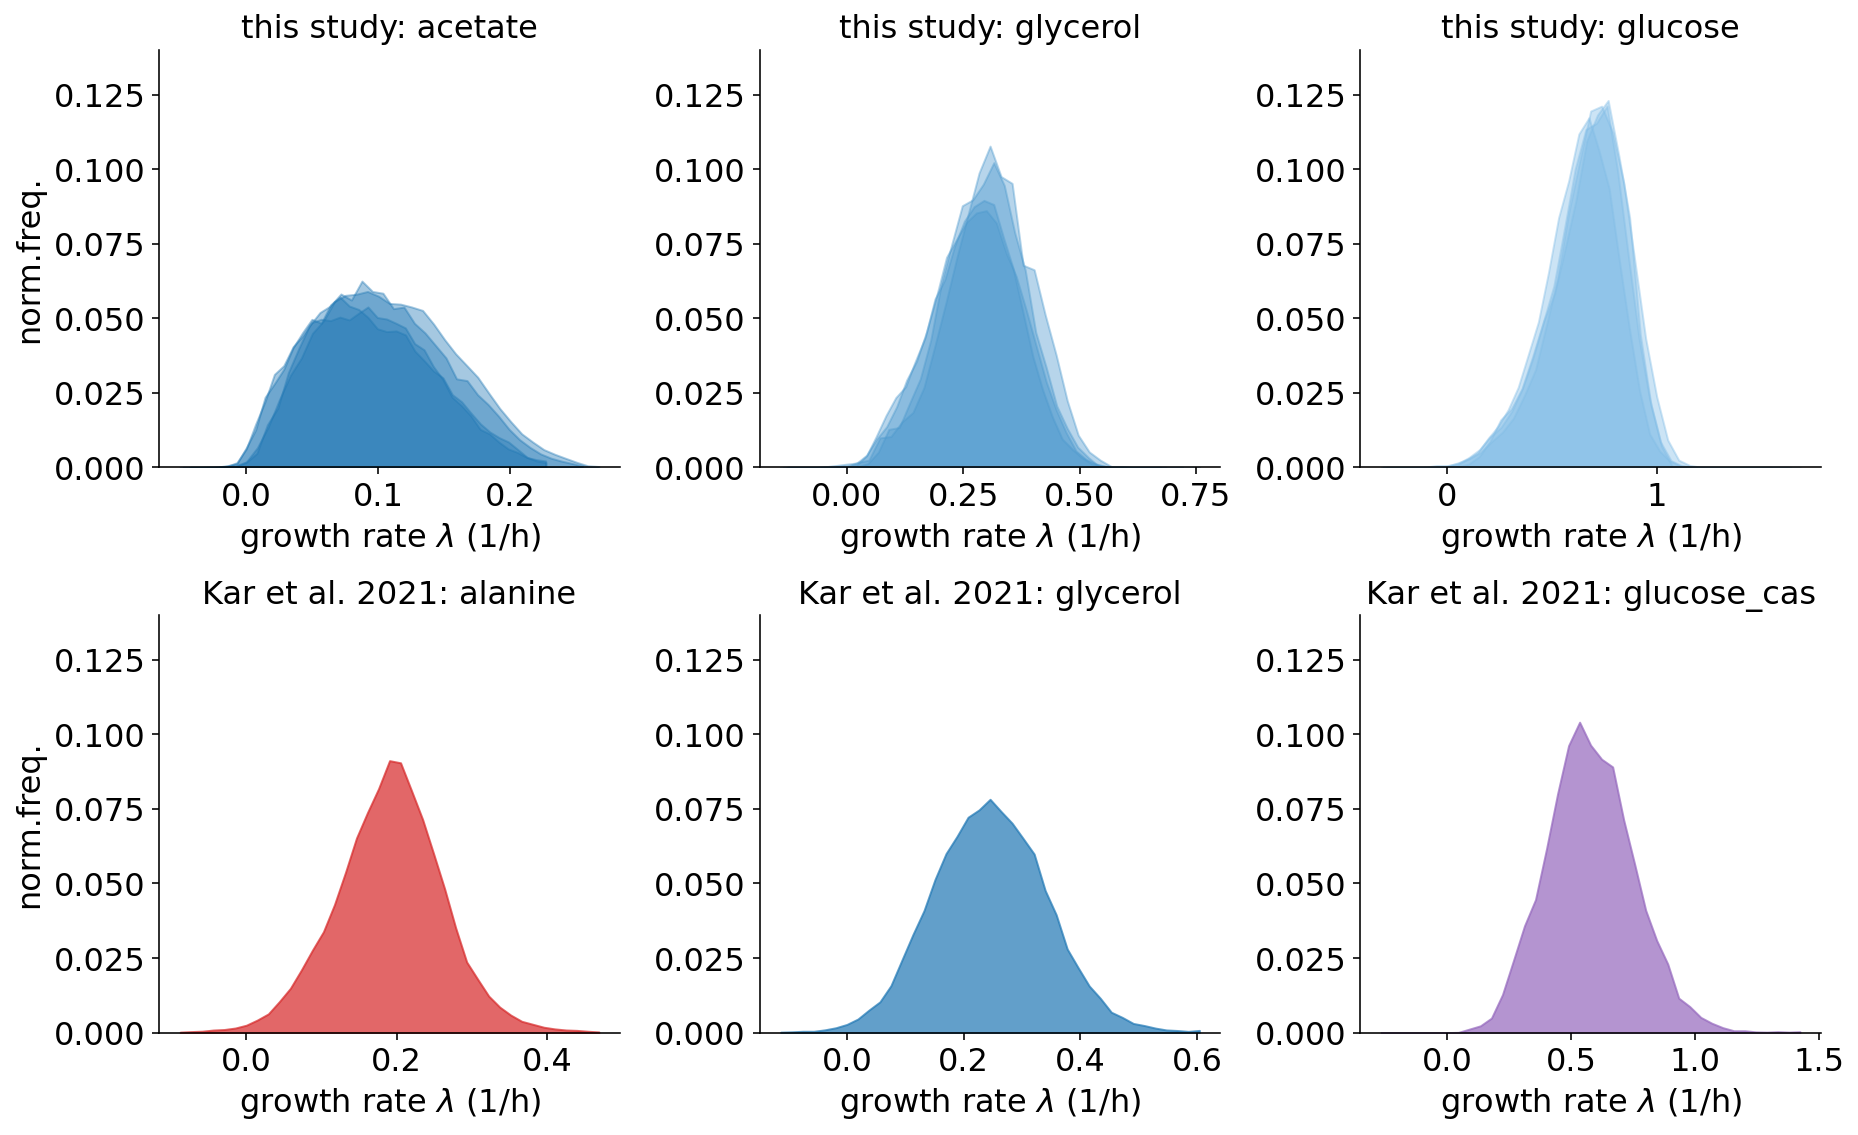

In [198]:


def bin_arr(means, n_bins=1000, return_edges=True, ignore_errors=False):
    if return_edges:
        return np.histogram(means, bins=n_bins)
    else:
        w, e = np.histogram(means, bins=n_bins)
        return w, e[:-1]+np.diff(e)/2.
    

def plot_growth_hists(cell_stats):

    fig, ax = plt.subplots(2,3, figsize=(FULL_SIZE,FULL_HEIGHT*2))

    for a in ax.ravel():
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        a.set_ylim(0,0.14)
        # a.set_xlim(-0.2,2.2)
        a.set_xlabel(r"growth rate $\lambda$ (1/h)")



    ax[0, 0].set_ylabel(r"norm.freq.")
    ax[1, 0].set_ylabel(r"norm.freq.")

    for j, c in enumerate(conditions):
        for ds in cell_stats.keys():
            if c+"_" not in ds:
                continue
            norm_l = cell_stats[ds]['l']/np.mean( cell_stats[ds]['l'])
            weight, bin_c = bin_arr(norm_l, return_edges=False, n_bins=np.linspace(-0.5, 2.5,40))
            weight= np.array(weight)/np.sum(weight)
            ax[0, j].fill_between(bin_c*np.mean( cell_stats[ds]['l'])*60, weight, alpha=0.4, color=color_by_condition[c])
            ax[0, j].set_title("this study: "+label_by_condition[c])

    for j, c in enumerate(cond_kar):
        for ds in cell_stats.keys():
            if c+"_" not in ds:
                continue
            norm_l = cell_stats[ds]['l']/np.mean( cell_stats[ds]['l'])
            weight, bin_c = bin_arr(norm_l, return_edges=False, n_bins=np.linspace(-0.5, 2.5,40))
            weight= np.array(weight)/np.sum(weight)
            ax[1, j].fill_between(bin_c*np.mean( cell_stats[ds]['l'])*60, weight, alpha=0.7, color=color_by_condition_Kar[c])
            ax[1, j].set_title("Kar et al. 2021: " +c)
            

    plt.tight_layout()

cond_kar = [file.split("_processed")[0].split("/")[-1] for file in prediction_files]
    
plot_growth_hists(cell_stats)


In [ ]:
input_dir = "../../ecoli_other_labs/Kar2021/RealTrace_out/"


corralations_filenames = get_input_files(input_dir, keyword="correlations", ext=".csv")
# Filter if wanted
corralations_filenames = [cf for cf in corralations_filenames if cf.split("/")[-1].split("_")[1]]
corralations_filenames = np.sort(corralations_filenames)

corralations_filenames = [corralations_filenames[0], corralations_filenames[2], corralations_filenames[1]]

corr_dict_all = {}
gamma_lambdas = {}
mean_lambdas = {}
mean_qs = {}
gamma_qs = {}
mean_sq_conc = {}

def get_mean_growth_rate(cells):
    mean_lambda = np.sum(np.concatenate([np.array(cell.mean_l)/np.array(cell.cov_ll) for cell in cells])) \
                /np.sum(np.concatenate([1./np.array(cell.cov_ll) for cell in cells]))
    return mean_lambda
    
for cf in corralations_filenames:
    correlations_df = pd.read_csv(cf, index_col=False)

    data_set_name = re.split('_pro', cf.split('/')[-1] )[0]
    print(data_set_name, end="\t") 

    corr_dict_all[data_set_name] = [correlations_df["dt"], correlations_df["corr_l(t+dt)l(t)"],  correlations_df["corr_l(t+dt)l(t)_err"]]
    
    # Collect relevant parameters 
    # gamma_lambdas[data_set_name] = data['gamma_lambda']
    # mean_lambdas[data_set_name] = data['mean_lambda']
        
    prediction_file = cf.replace("correlations.csv", "prediction.csv")
    cells = df2ggp_cells(pd.read_csv(prediction_file, skiprows=header_lines(prediction_file), 
                                 dtype={"parent_id":str, "cell_id":str}))
    
    mean_lambdas[data_set_name] = get_mean_growth_rate(cells)


alanine	glycerol	glucose_cas	

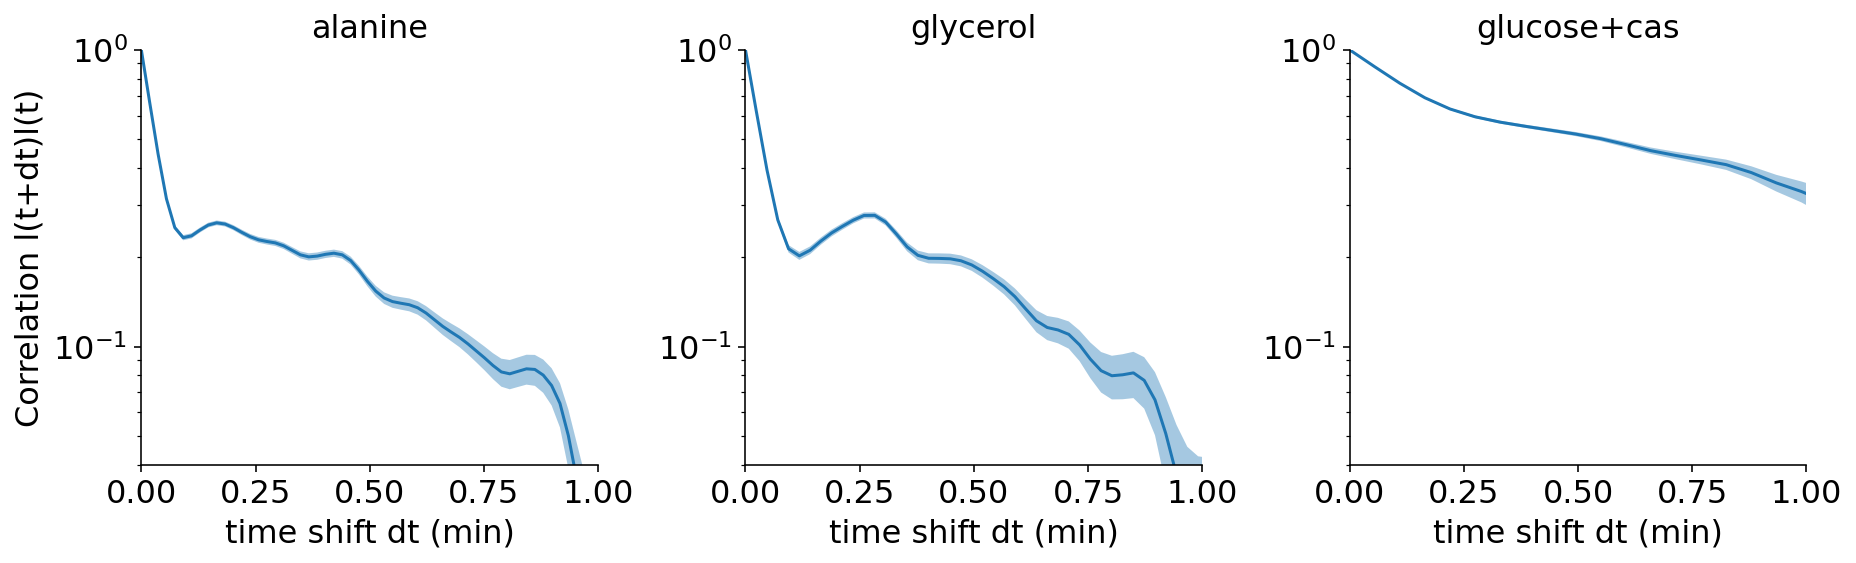

In [199]:



input_dir = "../../ecoli_other_labs/Kar2021/RealTrace_out/"


corralations_filenames = get_input_files(input_dir, keyword="correlations", ext=".csv")
# Filter if wanted
corralations_filenames = [cf for cf in corralations_filenames if cf.split("/")[-1].split("_")[1]]
corralations_filenames = np.sort(corralations_filenames)

corralations_filenames = [corralations_filenames[0], corralations_filenames[2], corralations_filenames[1]]

corr_dict_all = {}
gamma_lambdas = {}
mean_lambdas = {}
mean_qs = {}
gamma_qs = {}
mean_sq_conc = {}

def get_mean_growth_rate(cells):
    mean_lambda = np.sum(np.concatenate([np.array(cell.mean_l)/np.array(cell.cov_ll) for cell in cells])) \
                /np.sum(np.concatenate([1./np.array(cell.cov_ll) for cell in cells]))
    return mean_lambda
    
for cf in corralations_filenames:
    correlations_df = pd.read_csv(cf, index_col=False)

    data_set_name = re.split('_pro', cf.split('/')[-1] )[0]
    print(data_set_name, end="\t") 

    corr_dict_all[data_set_name] = [correlations_df["dt"], correlations_df["corr_l(t+dt)l(t)"],  correlations_df["corr_l(t+dt)l(t)_err"]]
    
    # Collect relevant parameters 
    # gamma_lambdas[data_set_name] = data['gamma_lambda']
    # mean_lambdas[data_set_name] = data['mean_lambda']
        
    prediction_file = cf.replace("correlations.csv", "prediction.csv")
    cells = df2ggp_cells(pd.read_csv(prediction_file, skiprows=header_lines(prediction_file), 
                                 dtype={"parent_id":str, "cell_id":str}))
    
    mean_lambdas[data_set_name] = get_mean_growth_rate(cells)






def plot_correlations(corr_dict_all, mean_lambdas):
    fig, ax = plt.subplots(1,3, figsize=(FULL_SIZE,FULL_HEIGHT))
    ax = ax.ravel()

    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        a.set_xlabel("time shift dt (min)")
        a.set_xlim(0,1)
        a.set_ylim(0.04,1)
        a.set_yscale('log')
        
        
    # Layout
    ax[0].set_ylabel("Correlation l(t+dt)l(t)")

    for i, ds in enumerate(corr_dict_all.keys()):
        dts = copy.deepcopy(corr_dict_all[ds][0])
        rs = copy.deepcopy(corr_dict_all[ds][1])
        errs = copy.deepcopy(corr_dict_all[ds][2])
        
        dts /= (np.log(2.)/mean_lambdas[ds])
        ax[i].plot(dts, rs)
        ax[i].fill_between(dts, rs-errs, rs+errs, alpha=0.4)

        ax[i].set_title(ds.replace("_", "+"))
    plt.tight_layout()

    
plot_correlations(corr_dict_all, mean_lambdas)
